# Dataset Understanding, EDA and Preprocessing

**Roles:** Member 2 — Dataset Analysis and Understanding; Member 3 — Data Preprocessing and EDA. This notebook prepares reproducible data splits for the MLP and baseline team. It does not train or evaluate models.

## Section 1 — Setup and Dataset Loading

Load the original CSV without modifying it. The path is resolved from the notebook's working directory or a parent project directory.

In [1]:
from pathlib import Path

import json
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_SEED = 42
DATASET_NAME = "diabetes_binary_5050split_health_indicators_BRFSS2015.csv"
PROJECT_ROOT = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / "Data" / "raw").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not find the project Data/raw directory.")

DATA_PATH = PROJECT_ROOT / "Data" / "raw" / DATASET_NAME
PROCESSED_PATH = PROJECT_ROOT / "Data" / "processed"
FIGURES_PATH = PROJECT_ROOT / "reports" / "figures"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
df = pd.read_csv(DATA_PATH)
if df.empty:
    raise ValueError("The dataset is empty.")

print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {DATA_PATH.name}.")
display(df.head())

Loaded 70,692 rows and 22 columns from diabetes_binary_5050split_health_indicators_BRFSS2015.csv.


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## Section 2 — Dataset Understanding

Inspect the schema, concise descriptive statistics, target balance, and identify the target and input features. The printed interpretation is based on the loaded data.

In [2]:
TARGET = "Diabetes_binary"
if TARGET not in df.columns:
    raise KeyError(f"Expected target column {TARGET!r} is missing.")
if not df.columns.is_unique:
    raise ValueError("Column names must be unique.")

FEATURES = [column for column in df.columns if column != TARGET]
X = df[FEATURES].copy()
y = df[TARGET].copy()

schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=True),
})
print(f"Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns")
display(schema)
print("Descriptive statistics:")
display(df.describe().T[["count", "mean", "std", "min", "50%", "max"]].round(2))

class_counts = y.value_counts().sort_index()
class_summary = pd.DataFrame({
    "count": class_counts,
    "percent": (class_counts / len(y) * 100).round(2),
})
print(f"Target: {TARGET}; input features: {len(FEATURES)}")
display(class_summary)
print(
    f"Interpretation: {len(df):,} structured health-indicator records; "
    f"target values are {sorted(y.dropna().unique().tolist())}. "
    f"Class proportions are {class_summary['percent'].to_dict()}."
)

Dimensions: 70,692 rows x 22 columns


,dtype,unique_values
Diabetes_binary,float64,2
HighBP,float64,2
HighChol,float64,2
CholCheck,float64,2
BMI,float64,80
Smoker,float64,2
Stroke,float64,2
HeartDiseaseorAttack,float64,2
PhysActivity,float64,2
Fruits,float64,2


Descriptive statistics:


,count,mean,std,min,50%,max
Diabetes_binary,70692.0,0.50,0.50,0.0,0.5,1.0
HighBP,70692.0,0.56,0.50,0.0,1.0,1.0
HighChol,70692.0,0.53,0.50,0.0,1.0,1.0
CholCheck,70692.0,0.98,0.16,0.0,1.0,1.0
BMI,70692.0,29.86,7.11,12.0,29.0,98.0
Smoker,70692.0,0.48,0.50,0.0,0.0,1.0
Stroke,70692.0,0.06,0.24,0.0,0.0,1.0
HeartDiseaseorAttack,70692.0,0.15,0.35,0.0,0.0,1.0
PhysActivity,70692.0,0.70,0.46,0.0,1.0,1.0
Fruits,70692.0,0.61,0.49,0.0,1.0,1.0


Target: Diabetes_binary; input features: 21


,count,percent
Diabetes_binary,,
0.0,35346,50.0
1.0,35346,50.0


Interpretation: 70,692 structured health-indicator records; target values are [0.0, 1.0]. Class proportions are {0.0: 50.0, 1.0: 50.0}.


## Section 3 — Data Quality Analysis

Check missingness, repeated records, numeric validity, binary target/indicator codes, and BMI values flagged by the IQR rule. A flag is not proof of an error and does not trigger deletion.

In [3]:
missing_cells = int(df.isna().sum().sum())
duplicate_rows = int(df.duplicated().sum())
if missing_cells:
    raise ValueError(
        f"Found {missing_cells} missing cells. Inspect them and choose a justified "
        "train-fitted imputation strategy before proceeding."
    )
if not all(pd.api.types.is_numeric_dtype(df[column]) for column in df.columns):
    raise TypeError("All dataset columns must be numeric for this preprocessing workflow.")
if not np.isfinite(df.to_numpy()).all():
    raise ValueError("The dataset contains infinite or non-finite numeric values.")
if not y.isin([0, 1]).all():
    raise ValueError("The target must contain only 0 and 1.")

binary_indicators = [
    column for column in FEATURES
    if set(df[column].unique()).issubset({0, 1})
]
coded_features = [column for column in FEATURES if column not in binary_indicators]
print("Observed ranges for multi-valued features:")
display(df[coded_features].agg(["min", "max", "nunique"]).T)

feature_groups = pd.MultiIndex.from_frame(X).factorize(sort=True)[0]
group_targets = pd.DataFrame({"group": feature_groups, "target": y.to_numpy()})
group_target_counts = group_targets.groupby("group")["target"].nunique()
conflicting_groups = int(group_target_counts.gt(1).sum())
repeated_feature_rows = int(X.duplicated().sum())

q1, q3 = X["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
bmi_outlier_count = int(((X["BMI"] < q1 - 1.5 * iqr) | (X["BMI"] > q3 + 1.5 * iqr)).sum())

print(f"Missing cells: {missing_cells:,}; exact repeated rows: {duplicate_rows:,}.")
print(
    f"Repeated feature rows: {repeated_feature_rows:,}; "
    f"feature patterns with both target values: {conflicting_groups:,}."
)
print(f"0/1 indicator columns observed: {len(binary_indicators)}; target values: {sorted(y.unique().tolist())}.")
print(f"BMI IQR-flagged values: {bmi_outlier_count:,} (retained; no automatic outlier removal).")
print(
    "Decision: no missing-value treatment is needed. Retain repeated rows because "
    "there is no respondent ID to establish that they are erroneous; group identical "
    "feature vectors together when splitting. The original codebook is not in the "
    "repository, so other encoded-value ranges are documented as observed, not "
    "independently validated against domain definitions."
)

Observed ranges for multi-valued features:


,min,max,nunique
BMI,12.0,98.0,80.0
GenHlth,1.0,5.0,5.0
MentHlth,0.0,30.0,31.0
PhysHlth,0.0,30.0,31.0
Age,1.0,13.0,13.0
Education,1.0,6.0,6.0
Income,1.0,8.0,8.0


Missing cells: 0; exact repeated rows: 1,635.
Repeated feature rows: 2,043; feature patterns with both target values: 408.
0/1 indicator columns observed: 14; target values: [0.0, 1.0].
BMI IQR-flagged values: 2,181 (retained; no automatic outlier removal).
Decision: no missing-value treatment is needed. Retain repeated rows because there is no respondent ID to establish that they are erroneous; group identical feature vectors together when splitting. The original codebook is not in the repository, so other encoded-value ranges are documented as observed, not independently validated against domain definitions.


## Section 4 — Essential EDA

Show the target balance, BMI distribution, and target proportions across selected observed feature codes (HighBP, GenHlth, and Age). These plots are descriptive; a correlation matrix is omitted because mixed binary and coded ordinal values can make simple correlations misleading without the codebook.

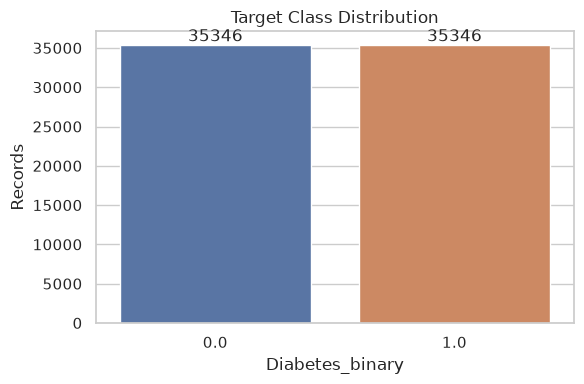

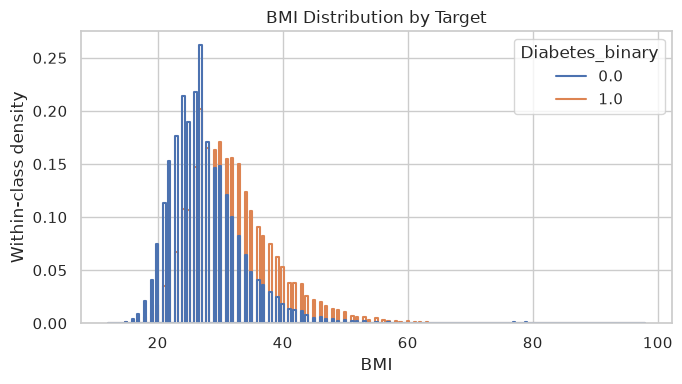

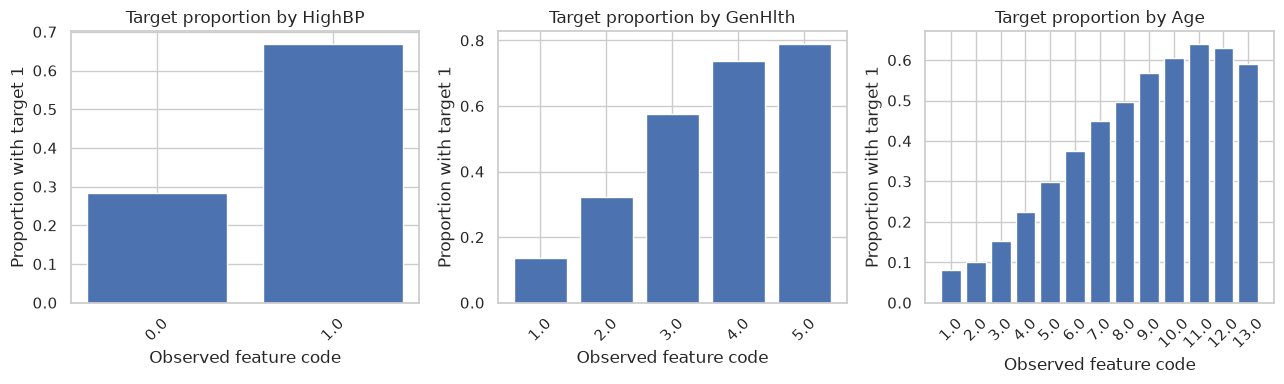

Interpretation: plots show observed distributions and associations only; they do not establish causality or justify dropping features.


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x=TARGET, hue=TARGET, legend=False, ax=ax)
ax.set(title="Target Class Distribution", xlabel="Diabetes_binary", ylabel="Records")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%d")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "target_class_distribution.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(
    data=df, x="BMI", hue=TARGET, stat="density", common_norm=False,
    element="step", fill=False, ax=ax,
)
ax.set(title="BMI Distribution by Target", xlabel="BMI", ylabel="Within-class density")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "bmi_by_target.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column in zip(axes, ["HighBP", "GenHlth", "Age"]):
    target_rate = df.groupby(column, observed=True)[TARGET].mean()
    ax.bar(target_rate.index.astype(str), target_rate.values)
    ax.tick_params(axis="x", labelrotation=45)
    ax.set(
        title=f"Target proportion by {column}",
        xlabel="Observed feature code",
        ylabel="Proportion with target 1",
    )
fig.tight_layout()
fig.savefig(FIGURES_PATH / "selected_features_by_target.png", dpi=200, bbox_inches="tight")
display(fig)
plt.close(fig)

print("Interpretation: plots show observed distributions and associations only; they do not establish causality or justify dropping features.")

## Section 5 — Data Preprocessing

No rows are removed: repeated feature patterns include conflicting targets, so deduplication would make an unsupported label choice. Keep 0/1 indicators and other numeric survey codes as numeric inputs; do not one-hot encode them without the codebook. Standardize numeric inputs for the MLP, fitting the scaler on training data only in Section 6. The original research paper is not present in the repository, so its specific preprocessing requirements cannot be verified.

In [5]:
preprocessor = Pipeline([("standard_scaler", StandardScaler())])
print("Preprocessing: preserve all numeric feature columns; StandardScaler is fitted after splitting.")
print(f"No imputation or row removal; {len(FEATURES)} features retained in their original order.")

Preprocessing: preserve all numeric feature columns; StandardScaler is fitted after splitting.
No imputation or row removal; 21 features retained in their original order.


## Section 6 — Final Dataset Preparation and Handoff

Use reproducible stratified group folds to create approximately 70%/15%/15% train/validation/test partitions. Grouping by the complete feature vector prevents repeated predictors (including conflicting labels) from crossing partitions while retaining all rows. Fit preprocessing on training features only, apply it consistently, and save the shared scaled splits, fitted pipeline, and compact metadata.

In [6]:
# Stratify unique feature groups by their target composition to avoid leakage.
group_summary = group_targets.groupby("group")["target"].agg(["min", "max"])
group_strata = np.where(
    group_summary["min"].eq(group_summary["max"]),
    group_summary["min"].astype(int).astype(str),
    "mixed",
)
group_ids = group_summary.index.to_numpy()
train_validation_groups, test_groups = train_test_split(
    group_ids,
    test_size=0.15,
    random_state=RANDOM_SEED,
    stratify=group_strata,
)
train_groups, validation_groups = train_test_split(
    train_validation_groups,
    test_size=0.15 / 0.85,
    random_state=RANDOM_SEED + 1,
    stratify=group_strata[np.isin(group_ids, train_validation_groups)],
)

train_indices = np.flatnonzero(np.isin(feature_groups, train_groups))
validation_indices = np.flatnonzero(np.isin(feature_groups, validation_groups))
test_indices = np.flatnonzero(np.isin(feature_groups, test_groups))
split_indices = {
    "train": train_indices,
    "validation": validation_indices,
    "test": test_indices,
}
X_train, y_train = X.iloc[train_indices], y.iloc[train_indices]
X_validation, y_validation = X.iloc[validation_indices], y.iloc[validation_indices]
X_test, y_test = X.iloc[test_indices], y.iloc[test_indices]

X_train_scaled = pd.DataFrame(
    preprocessor.fit_transform(X_train), index=X_train.index, columns=FEATURES
)
X_validation_scaled = pd.DataFrame(
    preprocessor.transform(X_validation), index=X_validation.index, columns=FEATURES
)
X_test_scaled = pd.DataFrame(
    preprocessor.transform(X_test), index=X_test.index, columns=FEATURES
)

split_groups = {
    name: set(feature_groups[indices]) for name, indices in split_indices.items()
}
assert sum(len(indices) for indices in split_indices.values()) == len(df)
assert not (split_groups["train"] & split_groups["validation"])
assert not (split_groups["train"] & split_groups["test"])
assert not (split_groups["validation"] & split_groups["test"])
assert all(frame.columns.tolist() == FEATURES for frame in [X_train_scaled, X_validation_scaled, X_test_scaled])
assert all(np.isfinite(frame.to_numpy()).all() for frame in [X_train_scaled, X_validation_scaled, X_test_scaled])

scaled_splits = {
    "train": (X_train_scaled, y_train),
    "validation": (X_validation_scaled, y_validation),
    "test": (X_test_scaled, y_test),
}
summary_rows = []
for name, (features, labels) in scaled_splits.items():
    reference_mean = X_train_scaled.mean()
    max_mean_difference = float((features.mean() - reference_mean).abs().max())
    summary_rows.append({
        "split": name,
        "rows": len(features),
        "target_1_percent": round(float(labels.mean() * 100), 2),
        "max_feature_mean_difference_vs_train_sd": round(max_mean_difference, 3),
    })
display(pd.DataFrame(summary_rows).set_index("split"))

for name, (features, labels) in scaled_splits.items():
    output = features.copy()
    output.insert(0, "source_row_index", features.index.astype("int64"))
    output[TARGET] = labels.to_numpy(dtype="int8")
    output.to_csv(PROCESSED_PATH / f"{name}_scaled.csv", index=False)

preprocessor_path = PROCESSED_PATH / "feature_preprocessor.joblib"
joblib.dump(preprocessor, preprocessor_path)
metadata = {
    "target": TARGET,
    "features": FEATURES,
    "source_row_index_column": "source_row_index (metadata only; exclude from model inputs)",
    "random_seed": RANDOM_SEED,
    "split_method": "Two-stage stratified group split by target composition; identical feature vectors stay in one partition",
    "split_rows": {name: len(indices) for name, indices in split_indices.items()},
    "preprocessing": "StandardScaler fitted on training features only",
}
metadata_path = PROCESSED_PATH / "split_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

# Validate the persisted split schemas and the reloaded train-fitted pipeline.
for name, (features, labels) in scaled_splits.items():
    saved = pd.read_csv(PROCESSED_PATH / f"{name}_scaled.csv")
    assert saved.columns.tolist() == ["source_row_index", *FEATURES, TARGET]
    assert len(saved) == len(features) == len(labels)
reloaded_preprocessor = joblib.load(preprocessor_path)
np.testing.assert_allclose(reloaded_preprocessor.transform(X_test), X_test_scaled.to_numpy())
assert all(set(labels.unique()) == {0, 1} for _, labels in scaled_splits.values())

print("Validation passed: all rows assigned once; feature groups do not cross splits; saved schemas and pipeline verified.")
print("Handoff: use *_scaled.csv for shared inputs; separate Diabetes_binary as y and drop source_row_index.")
print("Use validation for model selection and test once for final evaluation. No model was trained.")

,rows,target_1_percent,max_feature_mean_difference_vs_train_sd
split,,,
train,49503,50.03,0.000
validation,10594,49.90,0.015
test,10595,49.96,0.023


Validation passed: all rows assigned once; feature groups do not cross splits; saved schemas and pipeline verified.
Handoff: use *_scaled.csv for shared inputs; separate Diabetes_binary as y and drop source_row_index.
Use validation for model selection and test once for final evaluation. No model was trained.
